In [1]:
   %pip install --user -q segmentation-models-pytorch rasterio


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [1]:
# --- project root: run notebooks from the project folder
import os, sys
from pathlib import Path
_p = Path.cwd()
while not (_p / "preprocess.py").exists() and _p != _p.parent:
    _p = _p.parent
os.chdir(_p); sys.path.insert(0, str(_p))
print("working folder:", _p)

working folder: <project folder>


# 19 — Round 8: SegFormer v8 = v6 + ignore label borders (preprocessing step 1)

**Why:** WorldCover labels are least reliable exactly on the **boundaries between classes**: a 10 m pixel on the edge of a field
is often half field, half road or tree row (a *mixed pixel*), and the label can be shifted by one pixel against the radar image.
Training on these pixels teaches the model "wrong answers".

**What changes (only this):** in every *training* tile, each pixel that has a different class within `BORDER_PX` pixels
(a 3 × 3 window for `BORDER_PX = 1`) is set to **ignore**, so the loss never learns from it.

| | v6 | v8 |
|---|---|---|
| Model, inputs, loss, settings, data (`data_r5`) | — | **identical** to v6 |
| Training labels | all pixels | **class boundaries ignored** |
| Validation / test labels | all pixels | all pixels (unchanged → scores directly comparable) |

The labels on disk are **not** changed: the borders are removed on the fly when a tile is loaded (`train_lib_r8.py`).
Results go to `runs/C_segformer_v8_border/`. Afterwards, notebook 15 shows v8 next to v5 / v6 / v7 automatically.

## 1. Settings

In [2]:
CFG = dict(
    RUN_NAME="C_segformer_v8_border", MODEL_NAME="SegFormer v8 (v6 + label borders ignored)",
    ARCH="temporal_segformer_mitb2", FEATURES="12months+yearstats18+border_ignore",
    DATA="data_r5", WEIGHTS="imagenet",
    EPOCHS=60, WARMUP_EPOCHS=5, BATCH_SIZE=8, EVAL_BATCH=2,
    LR=6e-5, LR_NEW=1e-3, WEIGHT_DECAY=0.01, PATIENCE=12, LOSS="lovasz",
    NOISE_DB=2.0, ROLL=True, MONTH_DROP=0.1, TEMP_DIM=24, FUSE_DIM=32,
    NUM_WORKERS=0, SEED=42,
    BORDER_PX=1)                       # 1 = ignore pixels within 1 px of another class (3 x 3 window); 0 = off (= v6)
# Out of GPU memory? -> BATCH_SIZE=4 (and restart the kernel).

## 2. Setup

In [3]:
import json, random
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from preprocess import CLASSES, COLORS, IGNORE, load_stats
from train_lib_r8 import *                                     # = train_lib_r6 + border ignore

random.seed(CFG["SEED"]); np.random.seed(CFG["SEED"]); torch.manual_seed(CFG["SEED"])
RUN = Path("runs") / CFG["RUN_NAME"]; RUN.mkdir(parents=True, exist_ok=True)
json.dump(CFG, open(RUN / "config.json", "w"), indent=2)
DATA = Path(CFG["DATA"])
mstats = load_stats(DATA / "norm_stats.json")                 # monthly VV, VH, VV-VH mean / std (as v5)
index = pd.read_csv(DATA / "patch_index.csv")
index["file"] = index["file"].str.replace("\\", "/", regex=False)
print("device:", DEV, "|", torch.cuda.get_device_name(0) if DEV == "cuda" else "no GPU - training would be very slow")
print(index.split.value_counts().to_dict())

device: cuda | NVIDIA RTX A6000
{'train': 950, 'val': 128, 'test': 96}


## 3. Step 2 — the 18 year statistics
Computed per pixel over the 12 months. Their average and spread over the training patches are used to rescale them
(computed once from 300 training patches and saved as `data_r5/norm_stats_r6_yearstats.json`).

In [4]:
ystats = year_stat_norm(index, DATA)
display(pd.DataFrame({"mean": ystats["mean"], "std": ystats["std"]}, index=ystats["names"]).round(2).T)

,VV_median,VV_p10,VV_p90,VV_min,VV_max,VV_range,VH_median,VH_p10,VH_p90,VH_min,VH_max,VH_range,VV_VH_median,VV_VH_p10,VV_VH_p90,VV_VH_min,VV_VH_max,VV_VH_range
mean,-11.48,-13.17,-9.80,-13.97,-8.96,5.01,-19.19,-21.11,-17.29,-22.00,-16.38,5.61,7.68,5.69,9.68,4.73,10.72,5.99
std,4.88,5.07,4.72,5.17,4.69,2.38,5.23,5.44,5.01,5.54,5.00,2.91,2.23,2.17,2.48,2.28,2.73,2.44


### Step 1 — what "ignore label borders" removes
Left: the WorldCover label of a training tile. Middle: the pixels that are ignored (black). Right: the label the model learns from.
The table counts, over a sample of training tiles, how many pixels of each class are ignored.

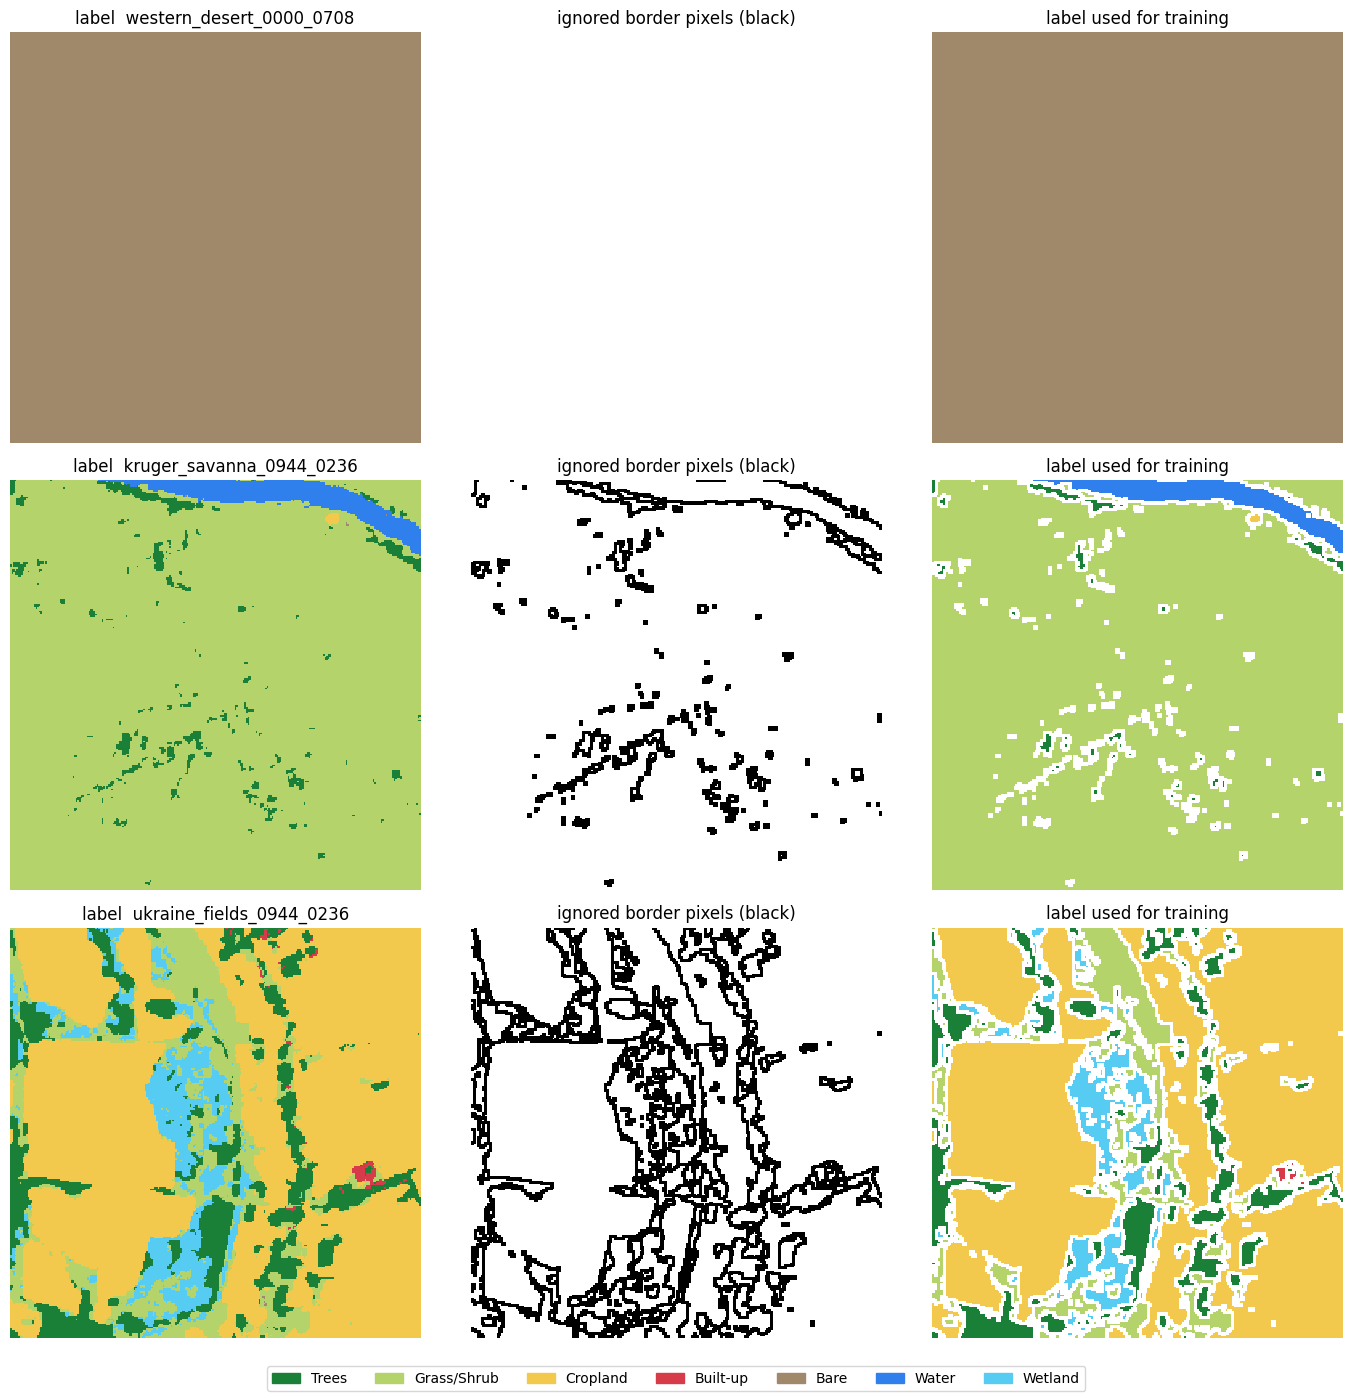

Training pixels ignored overall: 15.3 %  (sample of 200 tiles)


,pixels before,pixels after,ignored %,share before %,share after %
Trees,1502122.0,1070440.0,28.7,11.5,9.6
Grass/Shrub,2953807.0,2422279.0,18.0,22.5,21.8
Cropland,2134684.0,1922805.0,9.9,16.3,17.3
Built-up,2248725.0,1706763.0,24.1,17.2,15.4
Bare,1337306.0,1180100.0,11.8,10.2,10.6
Water,1537974.0,1499064.0,2.5,11.7,13.5
Wetland,1392582.0,1295860.0,6.9,10.6,11.7


In [5]:
from matplotlib.colors import ListedColormap
cmap = ListedColormap(COLORS)
tr = index[index.split == "train"]
fig, ax = plt.subplots(3, 3, figsize=(14, 14))
for row, f in zip(ax, tr.file.sample(3, random_state=3)):
    y = np.load(DATA / f)["y"]
    yb = ignore_borders(y, CFG["BORDER_PX"])
    row[0].imshow(np.ma.masked_equal(y, IGNORE), cmap=cmap, vmin=0, vmax=len(CLASSES) - 1, interpolation="nearest"); row[0].set_title(f"label  {Path(f).stem}")
    row[1].imshow((yb == IGNORE) & (y != IGNORE), cmap="gray_r", interpolation="nearest"); row[1].set_title("ignored border pixels (black)")
    row[2].imshow(np.ma.masked_equal(yb, IGNORE), cmap=cmap, vmin=0, vmax=len(CLASSES) - 1, interpolation="nearest"); row[2].set_title("label used for training")
    for a in row: a.axis("off")
fig.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS], CLASSES, loc="lower center", ncol=7)
plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.savefig(RUN / "border_examples.png", dpi=100); plt.show()

before = np.zeros(len(CLASSES)); after = np.zeros(len(CLASSES))
for f in tr.file.sample(min(200, len(tr)), random_state=0):
    y = np.load(DATA / f)["y"]; yb = ignore_borders(y, CFG["BORDER_PX"])
    before += np.bincount(y[y != IGNORE], minlength=len(CLASSES)); after += np.bincount(yb[yb != IGNORE], minlength=len(CLASSES))
tab = pd.DataFrame({"pixels before": before, "pixels after": after, "ignored %": (1 - after / before) * 100,
                    "share before %": before / before.sum() * 100, "share after %": after / after.sum() * 100}, index=CLASSES)
print(f"Training pixels ignored overall: {(1 - after.sum() / before.sum()) * 100:.1f} %  (sample of {min(200, len(tr))} tiles)")
display(tab.round(1)); tab.to_csv(RUN / "border_ignored_pixels.csv")

## 4. Data and model

In [6]:
train_dl, val_dl = make_loaders_border(CFG, DATA, index)
model = build_model(CFG, mstats, ystats, CFG["WEIGHTS"]).to(DEV)
loss_fn = make_loss(CFG, mstats)
print(f"parameters: {count_params(model):.1f} M  (same as v6) - temporal encoder + fusion: "
      f"{(count_params(model.temporal) + count_params(model.fuse)) * 1000:.1f} k")

# quick check: one batch through the model
x, m, y = next(iter(train_dl))
with torch.no_grad(), torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEV == "cuda")):
    out = model(x.to(DEV), m.to(DEV))
print("input", tuple(x.shape), "(batch, months, bands, H, W) | output", tuple(out.shape), "(batch, classes, H, W)")

loading val:   0%|          | 0/128 [00:00<?, ?it/s]

train patches 950 (label borders of 1 px ignored) | val patches 128 (full labels, x 12 months each)


config.json:   0%|          | 0.00/135 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/98.9M [00:00<?, ?B/s]

parameters: 24.8 M  (same as v6) - temporal encoder + fusion: 7.1 k
input (8, 12, 3, 256, 256) (batch, months, bands, H, W) | output (8, 7, 256, 256) (batch, classes, H, W)


## 5. Train
Resumes automatically from `last.pth` if the kernel stops. One epoch ≈ a few minutes on the GPU.

In [7]:
history = train(model, CFG, RUN, train_dl, val_dl, loss_fn)

epoch 0:   0%|          | 0/118 [00:00<?, ?it/s]

ep  0 | train 1.795 | val 1.679 | OA 0.710 | mIoU 0.474  *best* | 70s


epoch 1:   0%|          | 0/118 [00:00<?, ?it/s]

ep  1 | train 1.120 | val 1.727 | OA 0.702 | mIoU 0.477  *best* | 67s


epoch 2:   0%|          | 0/118 [00:00<?, ?it/s]

ep  2 | train 0.896 | val 1.897 | OA 0.662 | mIoU 0.471 | 67s


... (84 outputs left out)

epoch 45:   0%|          | 0/118 [00:00<?, ?it/s]

ep 45 | train 0.277 | val 1.345 | OA 0.820 | mIoU 0.621 | 67s


epoch 46:   0%|          | 0/118 [00:00<?, ?it/s]

ep 46 | train 0.275 | val 1.333 | OA 0.813 | mIoU 0.622 | 67s
Early stopping.
Done. Best val mIoU: 0.6545


## 6. Results on validation (best checkpoint)

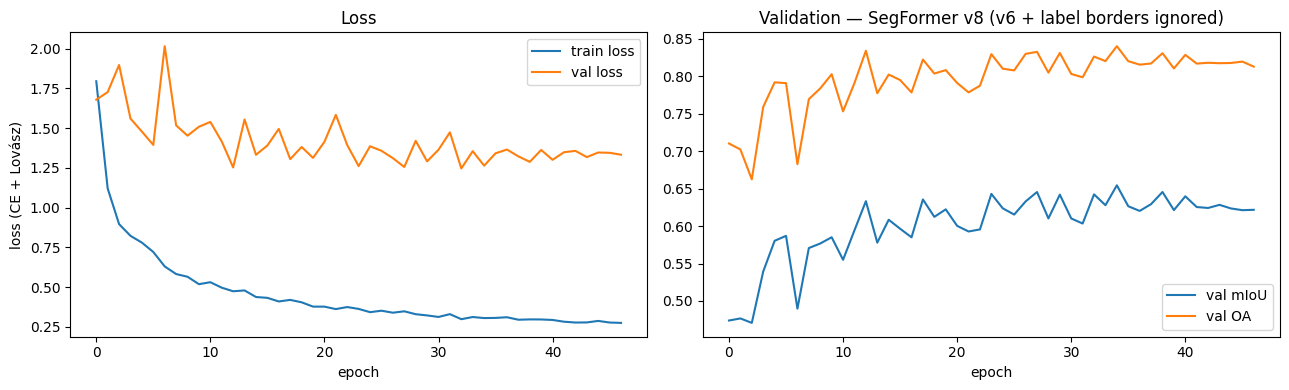

SegFormer v8 (v6 + label borders ignored) - val: OA 0.840 | mIoU 0.654 | best / worst month mIoU 0.655 / 0.654 (spread 0.002)


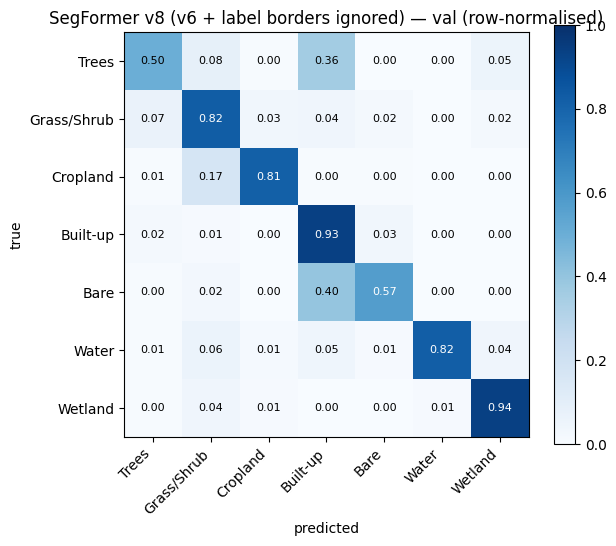

Validation, v6 vs v8 (the only difference: label borders ignored in training)


,v6 IoU,v8 IoU,v8 - v6
Trees,0.441,0.413,-0.028
Grass/Shrub,0.705,0.700,-0.005
Cropland,0.693,0.733,0.040
Built-up,0.790,0.788,-0.002
Bare,0.291,0.293,0.002
Water,0.751,0.765,0.014
Wetland,0.879,0.889,0.010
mIoU,0.650,0.654,0.004


In [8]:
plot_curves(RUN, CFG["MODEL_NAME"])
model.load_state_dict(torch.load(RUN / "best.pth", map_location=DEV))
val_table, val_month = report(model, CFG, RUN, val_dl, "val")

v6 = json.load(open("runs/C_segformer_v6/metrics.json"))
cmp = pd.DataFrame({"v6 IoU": pd.Series(v6["per_class_iou"]), "v8 IoU": val_table["IoU"].drop("mean")})
cmp.loc["mIoU"] = [v6["val_miou"], val_table.loc["mean", "IoU"]]
cmp["v8 - v6"] = cmp["v8 IoU"] - cmp["v6 IoU"]
print("Validation, v6 vs v8 (the only difference: label borders ignored in training)"); display(cmp.round(3))

## 7. Do the months differ now?
Check that ignoring borders did not make the maps less stable over the months. Below: mIoU per month (validation) and four months of one validation tile.

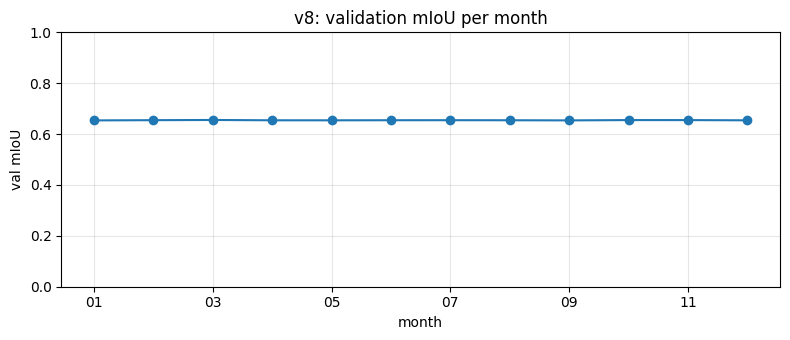

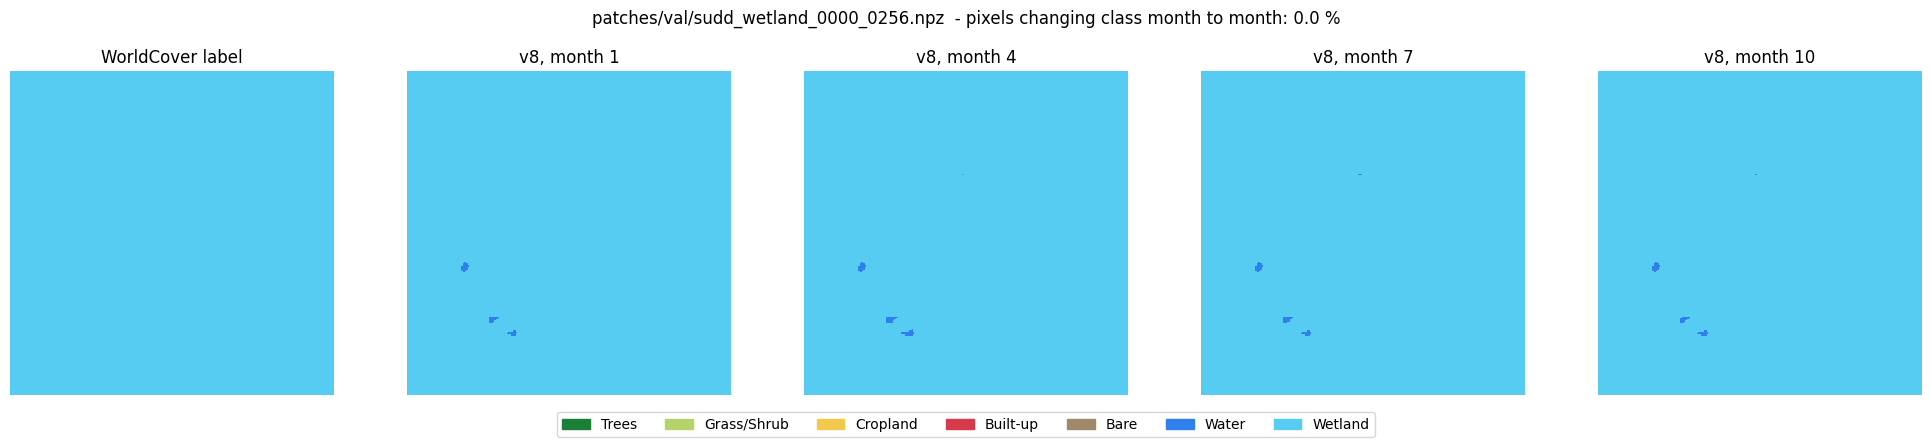

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.5))
val_month.plot(ax=ax, marker="o"); ax.set_ylim(0, 1); ax.set_xlabel("month"); ax.set_ylabel("val mIoU"); ax.grid(alpha=0.3)
ax.set_title("v8: validation mIoU per month"); plt.tight_layout(); plt.show()

from matplotlib.colors import ListedColormap
cmap = ListedColormap(COLORS)
ds = val_dl.dataset
k = int(np.argmax([float((y_ == 2).float().mean() + (y_ == 6).float().mean()) for y_ in ds.ys]))   # a tile with crop / wetland
x, y = ds[k]
with torch.no_grad(), torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEV == "cuda")):
    e = model.encode(x[None].to(DEV))
    preds = [model.decode(e, torch.tensor([m], device=DEV)).argmax(1)[0].cpu().numpy() for m in range(12)]
changed = np.mean([(preds[m] != preds[m - 1]).mean() for m in range(1, 12)]) * 100
fig, ax = plt.subplots(1, 5, figsize=(20, 4.4))
ax[0].imshow(np.ma.masked_equal(y.numpy(), IGNORE), cmap=cmap, vmin=0, vmax=len(CLASSES) - 1, interpolation="nearest"); ax[0].set_title("WorldCover label")
for a, m in zip(ax[1:], [0, 3, 6, 9]):
    a.imshow(preds[m], cmap=cmap, vmin=0, vmax=len(CLASSES) - 1, interpolation="nearest"); a.set_title(f"v8, month {m + 1}")
for a in ax: a.axis("off")
fig.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS], CLASSES, loc="lower center", ncol=7)
fig.suptitle(f"{ds.files[k]}  - pixels changing class month to month: {changed:.1f} %")
plt.tight_layout(rect=(0, 0.07, 1, 0.95)); plt.savefig(RUN / "val_months_example.png", dpi=110); plt.show()

## 8. Test set (final exam — only for reporting, not for choosing settings)
Same 6 test regions as v6 (values read from `runs/C_segformer_v6/metrics.json`).

loading test:   0%|          | 0/96 [00:00<?, ?it/s]

SegFormer v8 (v6 + label borders ignored) - test: OA 0.846 | mIoU 0.738 | best / worst month mIoU 0.743 / 0.735 (spread 0.008)


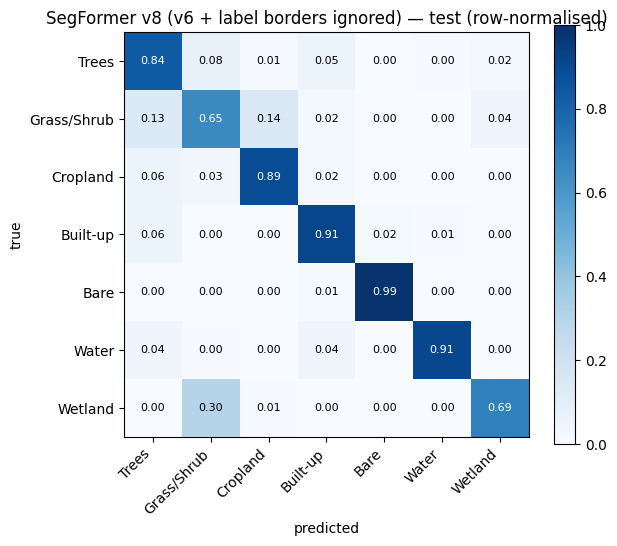

,v6 IoU,v8 IoU,v8 - v6
Trees,0.695,0.694,-0.001
Grass/Shrub,0.503,0.512,0.009
Cropland,0.714,0.722,0.008
Built-up,0.842,0.837,-0.005
Bare,0.969,0.964,-0.005
Water,0.848,0.837,-0.011
Wetland,0.540,0.599,0.059
mIoU,0.730,0.738,0.008


saved: ['best.pth', 'border_examples.png', 'border_ignored_pixels.csv', 'config.json', 'curves.png', 'history.csv', 'last.pth', 'metrics.json', 'test_confusion.png', 'test_per_class.csv', 'val_confusion.png', 'val_months_example.png', 'val_per_class.csv']


In [10]:
test_ds = EvalSeries(index[index.split == "test"].file, DATA, "loading test")
test_dl = torch.utils.data.DataLoader(test_ds, CFG["EVAL_BATCH"], shuffle=False)
test_table, test_month = report(model, CFG, RUN, test_dl, "test")
t = pd.DataFrame({"v6 IoU": pd.Series(v6.get("test_per_class_iou", {})), "v8 IoU": test_table["IoU"].drop("mean")})
t.loc["mIoU"] = [v6.get("test_miou", np.nan), test_table.loc["mean", "IoU"]]; t["v8 - v6"] = t["v8 IoU"] - t["v6 IoU"]
display(t.round(3))
print("saved:", sorted(p.name for p in RUN.iterdir()))

✅ **Share with me:** the border examples and table, the training curves and the two v6-vs-v8 tables.
Then open **notebook 15** and run it on your place: v8 is already in its `MODELS` list and appears next to v5 / v6 / v7.